# Geometric Probability

Companion notebook for [Geometric Probability](../../notes/probability/geometric_probability.md).

For a uniformly random point in a region, probability is a ratio of measures (length, area, volume). We compute the distance-from-a-corner probability in closed form, check it with Monte Carlo, and explore the sum of two uniforms and Bertrand's paradox.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from fractions import Fraction

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 3.5)
from scipy.integrate import quad

## 1. Distance from a corner of the unit square

$P(D<r)$ is the area of the quarter disk clipped to the square:

$$P(D<r)=\begin{cases}\pi r^2/4 & 0\le r\le1\\ r^2\left(\arcsin\frac1r-\frac\pi4\right)+\sqrt{r^2-1} & 1<r\le\sqrt2\\ 1 & r>\sqrt2.\end{cases}$$

In [2]:
def p_dist(r):
    if r <= 0:
        return 0.0
    if r <= 1:
        return np.pi * r**2 / 4
    if r <= np.sqrt(2):
        return r**2 * (np.arcsin(1 / r) - np.pi / 4) + np.sqrt(r**2 - 1)
    return 1.0

# Check against numerical integration of the clipped area: integral of min(1, sqrt(r^2 - x^2))
def p_numeric(r):
    val, _ = quad(lambda x: min(1.0, np.sqrt(max(r**2 - x**2, 0.0))), 0, 1)
    return val

for r in (0.5, 0.8, 1.0, 1.2, 1.4, 1.6):
    print(f"r={r}: closed form {p_dist(r):.4f}  numeric {p_numeric(r):.4f}")

r=0.5: closed form 0.1963  numeric 0.1963
r=0.8: closed form 0.5027  numeric 0.5027
r=1.0: closed form 0.7854  numeric 0.7854
r=1.2: closed form 0.9509  numeric 0.9509
r=1.4: closed form 0.9998  numeric 0.9998
r=1.6: closed form 1.0000  numeric 1.0000


## 2. Monte Carlo check and picture

r=0.8: simulated 0.5031  exact 0.5027
r=1.2: simulated 0.9509  exact 0.9509


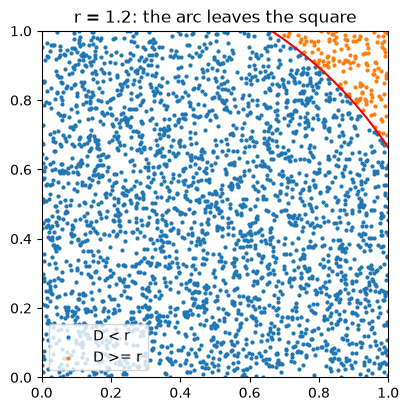

In [3]:
n = 200_000
pts = rng.random((n, 2))
d = np.hypot(pts[:, 0], pts[:, 1])
for r in (0.8, 1.2):
    print(f"r={r}: simulated {np.mean(d < r):.4f}  exact {p_dist(r):.4f}")

r = 1.2
fig, ax = plt.subplots(figsize=(4.5, 4.5))
sub = pts[:3000]
inside = np.hypot(sub[:, 0], sub[:, 1]) < r
ax.scatter(sub[inside, 0], sub[inside, 1], s=4, label="D < r")
ax.scatter(sub[~inside, 0], sub[~inside, 1], s=4, label="D >= r")
t = np.linspace(0, np.pi / 2, 200)
ax.plot(r * np.cos(t), r * np.sin(t), "r-")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.legend(loc="lower left")
ax.set_title("r = 1.2: the arc leaves the square")
plt.show()

## 3. Probability as a function of $r$

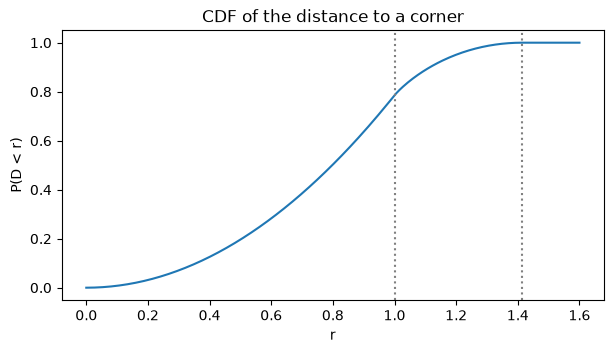

In [4]:
rs = np.linspace(0, 1.6, 300)
plt.plot(rs, [p_dist(x) for x in rs])
plt.axvline(1, color="gray", linestyle=":"); plt.axvline(np.sqrt(2), color="gray", linestyle=":")
plt.xlabel("r"); plt.ylabel("P(D < r)")
plt.title("CDF of the distance to a corner")
plt.show()

## 4. Sum and product of two uniform numbers

$P(X+Y<1)=\tfrac12$, $P(X+Y<1.5)=1-\tfrac{1}{8}=0.875$, and $P(XY<\tfrac14)=\tfrac14+\tfrac14\ln4\approx0.5966$.

In [5]:
x, y = rng.random(n), rng.random(n)
print("P(X+Y<1)   sim", round(np.mean(x + y < 1), 4), " exact 0.5")
print("P(X+Y<1.5) sim", round(np.mean(x + y < 1.5), 4), " exact 0.875")
print("P(XY<1/4)  sim", round(np.mean(x * y < 0.25), 4), " exact", round(0.25 + 0.25 * np.log(4), 4))

P(X+Y<1)   sim 0.5002  exact 0.5
P(X+Y<1.5) sim 0.8742  exact 0.875
P(XY<1/4)  sim 0.5962  exact 0.5966


## 5. Bertrand's paradox

"A random chord is longer than the radius" has a different answer depending on how the chord is generated: random endpoints $\to\tfrac23$, random point along a radius $\to\tfrac{\sqrt3}{2}\approx0.866$, uniform midpoint in the disk $\to\tfrac34$ (the method used in the note).

In [6]:
R = 1.0
# 1. random endpoints on the circle
a, b = rng.uniform(0, 2 * np.pi, (2, n))
len1 = 2 * R * np.abs(np.sin((a - b) / 2))
# 2. midpoint at uniform distance along a random radius
d2 = rng.uniform(0, R, n)
len2 = 2 * np.sqrt(R**2 - d2**2)
# 3. midpoint uniform in the disk
rad = R * np.sqrt(rng.random(n))
len3 = 2 * np.sqrt(R**2 - rad**2)

for name, L, exact in [("random endpoints", len1, 2 / 3),
                       ("random radial point", len2, np.sqrt(3) / 2),
                       ("random midpoint in disk", len3, 3 / 4)]:
    print(f"{name:24s} simulated {np.mean(L > R):.4f}  exact {exact:.4f}")

random endpoints         simulated 0.6669  exact 0.6667
random radial point      simulated 0.8657  exact 0.8660
random midpoint in disk  simulated 0.7514  exact 0.7500


## 6. A meeting problem

Two friends arrive uniformly in a one-hour window and each waits 15 minutes. They meet iff $|X-Y|\le15$, so $P=1-(45/60)^2=0.4375$.

In [7]:
arrive = rng.uniform(0, 60, (n, 2))
print("simulated:", round(np.mean(np.abs(arrive[:, 0] - arrive[:, 1]) <= 15), 4), " exact:", 1 - (45 / 60) ** 2)

simulated: 0.4377  exact: 0.4375
